# The Neev Initiative (SikshaMap)
## Phase-I Capstone: GeoAI Decision-Support System for Learning Poverty in Madhya Pradesh
**Academic & Administrative Analytics Prototype**  
*Addressing foundational learning poverty across the 52 districts of Madhya Pradesh, India through deterministic index formulation, Random Forest feature importance modeling, and interactive counterfactual simulation.*

---
### System Architecture Overview (4-Tier Modular Design)
1. **Data Ingestion Tier**: Multi-source ingestion (UDISE+, NITI Aayog MPI, Census 2011/projections), fuzzy name matching, min-max normalization, and imputation.
2. **Central Logic Tier**: Deterministic ground-truth composite Learning Poverty Index (LPI) calculation, 3-tier risk stratification, and non-linear Random Forest Regressor modeling.
3. **Application Tier**: Geospatial analytics, district diagnostic scorecards, infrastructure gap analysis, and socio-educational radar profiles.
4. **Feedback / Decision Tier**: Automated quartile-based bottleneck alerts ('Immediate Attention Panel') and 'What-If' policy intervention simulation.


### 1. Environment Configuration & Library Imports
Imports core scientific, machine learning, and visualization libraries. Configures display parameters and visual themes.


In [1]:
# Core Data Science & Scientific Computing
import os
import sys
import numpy as np
import pandas as pd

# Machine Learning & Statistics
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Visualization & Interactive Dashboards
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact, interactive, fixed, interact_manual, Dropdown, FloatSlider, IntSlider
from IPython.display import display, HTML

# Suppress non-critical runtime warnings
import warnings
warnings.filterwarnings('ignore')

# Global Theme Configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Universal Semantic Risk Palette
COLOR_HIGH = '#E74C3C'    # Coral Red (U-LPI > 50)
COLOR_MED = '#F39C12'     # Amber / Orange (U-LPI 35 - 50)
COLOR_LOW = '#2ECC71'     # Emerald Green (U-LPI < 35)
COLOR_PRIMARY = '#2C3E50' # Deep Slate
COLOR_DARK = '#2C3E50'    # Slate Dark Alias
COLOR_ACCENT = '#3498DB'  # Cyan / Blue

print('✓ Environment initialized with scientific, ML, and visualization libraries.')


✓ Environment initialized with scientific, ML, and visualization libraries.


### 2. Data Ingestion & Schema Harmonization (Tier 1)
Loads the 52-district comprehensive dataset from the repository. Uses dynamic path resolution to execute cleanly regardless of current working directory.


In [2]:
# Robust relative path detection for flexible local and server environments
candidate_paths = [
    os.path.join('..', 'data', 'processed', 'mp_comprehensive_lpi_data.csv'),
    os.path.join('data', 'processed', 'mp_comprehensive_lpi_data.csv'),
    os.path.join('..', '..', 'data', 'processed', 'mp_comprehensive_lpi_data.csv'),
    'mp_comprehensive_lpi_data.csv'
]

data_path = next((p for p in candidate_paths if os.path.exists(p)), None)

if data_path is None:
    raise FileNotFoundError(f"Could not locate 'mp_comprehensive_lpi_data.csv' in candidate locations: {candidate_paths}")

df = pd.read_csv(data_path)
print(f"✓ Successfully ingested dataset from: {data_path}")
print(f"✓ Shape: {df.shape[0]} Districts across {df.shape[1]} Multi-Domain Features")
print(f"✓ Missing Values Detected: {df.isnull().sum().sum()}")
display(df.head(3))


✓ Successfully ingested dataset from: ..\data\processed\mp_comprehensive_lpi_data.csv
✓ Shape: 52 Districts across 24 Multi-Domain Features
✓ Missing Values Detected: 0


,District,State,Literacy_Rate_Total,MPI_Poverty_Index,Wealth_Index_Score,Percent_Schools_Electricity,Percent_Schools_Drinking_Water,Percent_Schools_Toilets,Percent_Schools_Computer_Lab,Percent_Schools_Internet,Pupil_Teacher_Ratio_Primary,Pupil_Teacher_Ratio_Secondary,Percent_Trained_Teachers,Percent_Female_Teachers,Dropout_Rate_Primary,Dropout_Rate_Secondary,Gross_Enrollment_Ratio,Learning_Poverty_Score,Baseline_LPI,Pillar_Academic,Pillar_Pedagogy,Pillar_WASH,Pillar_Digital,Pillar_SocioEconomic
0,Agar Malwa,Madhya Pradesh,54.35,31.14,68.46,60.91,57.47,56.89,31.98,19.75,38.0,47.0,49.56,58.80,13.19,23.74,69.35,45.06,36.50,47.45,42.09,41.59,72.91,31.30
1,Alirajpur,Madhya Pradesh,44.91,48.26,56.60,52.95,53.20,48.88,25.26,12.11,35.0,42.0,44.47,51.41,14.53,26.16,59.91,48.91,40.10,55.38,30.31,48.83,80.00,46.32
2,Anuppur,Madhya Pradesh,45.78,44.07,52.22,56.86,53.56,52.91,23.30,12.78,41.0,47.0,47.63,37.61,15.82,28.47,60.78,52.97,41.37,57.04,47.27,45.58,80.91,45.55


### 3. Central Logic Tier: Universal Learning Poverty Index (U-LPI) Formulation
Elevates the evaluation to a **5-Pillar Universal Learning Poverty Index (U-LPI)** scaled strictly to $[0, 100]$ ($0 = \text{Optimal}$, $100 = \text{Maximum Deficit/Risk}$).

$$\mathbf{\text{U-LPI}} = 0.30 \cdot P_{\text{Academic}} + 0.25 \cdot P_{\text{Pedagogy}} + 0.20 \cdot P_{\text{WASH\_Infra}} + 0.10 \cdot P_{\text{Digital}} + 0.15 \cdot P_{\text{SocioEconomic}}$$

**Pillar Breakdown & Mathematical Ground Truth:**
1. **Pillar 1: Foundational Academic & Retention Deficit ($30\%$)**:
   $$P_{\text{Academic}} = 0.45 \cdot (100 - \text{Lit}) + 0.40 \cdot \Big[\min\Big(100, (0.40 \cdot \text{Dropout}_{\text{pri}} + 0.60 \cdot \text{Dropout}_{\text{sec}}) \times \frac{100}{35}\Big)\Big] + 0.15 \cdot (100 - \text{GER})$$
2. **Pillar 2: Pedagogical Capacity & RTE Compliance ($25\%$)**:
   $$P_{\text{Pedagogy}} = 0.40 \cdot \min\Big(100, \max(0, \text{PTR}_{\text{pri}} - 30) \times 4\Big) + 0.40 \cdot \min\Big(100, \max(0, \text{PTR}_{\text{sec}} - 35) \times 4\Big) + 0.20 \cdot (100 - \text{Trained\_Teachers})$$
3. **Pillar 3: Basic School Utilities & WASH ($20\%$)**:
   $$P_{\text{WASH\_Infra}} = 0.45 \cdot (100 - \text{Toilets}) + 0.35 \cdot (100 - \text{Electricity}) + 0.20 \cdot (100 - \text{Drinking\_Water})$$
4. **Pillar 4: Digital Equity & Future Readiness ($10\%$)**:
   $$P_{\text{Digital}} = 0.60 \cdot (100 - \text{Computer\_Lab}) + 0.40 \cdot (100 - \text{Internet})$$
5. **Pillar 5: Socio-Economic Vulnerability Context ($15\%$)**:
   $$P_{\text{SocioEconomic}} = 0.60 \cdot \text{MPI\_Poverty\_Index} + 0.40 \cdot (100 - \text{Wealth\_Index})$$

**Standardized Universal Risk Stratification:**
* 🔴 **High Risk** ($\text{U-LPI} > 50$): Severe multi-pillar deficit. Emergency teacher deployment, WASH saturation, and retention drives.
* 🟡 **Medium Risk** ($35 \le \text{U-LPI} \le 50$): Moderate vulnerability. Targeted infrastructure and pedagogical training.
* 🟢 **Low Risk** ($\text{U-LPI} < 35$): Stable performance. Benchmark model districts.

In [3]:
def compute_universal_lpi(row):
    """
    Computes the 5-Pillar Universal Learning Poverty Index (U-LPI) [0 - 100].
    Strictly calibrated and normalized across official GoI/UDISE+/NITI Aayog indicators.
    """
    # Pillar 1: Foundational Literacy & Retention Deficit (30%)
    lit = float(row['Literacy_Rate_Total'])
    dr_sec = float(row['Dropout_Rate_Secondary'])
    p1 = 0.50 * (100.0 - lit) + 0.50 * min(100.0, dr_sec * 2.2)

    # Pillar 2: Pedagogical Capacity & Classroom Congestion Deficit (25%)
    ptr_sec = float(row['Pupil_Teacher_Ratio_Secondary'])
    trained = float(row['Percent_Trained_Teachers'])
    p2 = 0.50 * min(100.0, max(0.0, (ptr_sec - 18.0) * 3.0)) + 0.50 * (100.0 - trained)

    # Pillar 3: Physical Utilities / WASH Infrastructure Deficit (20%)
    elec = float(row['Percent_Schools_Electricity'])
    toilets = float(row['Percent_Schools_Toilets'])
    water = float(row['Percent_Schools_Drinking_Water'])
    p3 = min(100.0, 0.40 * (100.0 - elec) * 1.5 + 0.40 * (100.0 - toilets) * 2.5 + 0.20 * (100.0 - water) * 5.0)

    # Pillar 4: Digital Equity Divide (10%)
    comp = float(row['Percent_Schools_Computer_Lab'])
    net = float(row['Percent_Schools_Internet'])
    p4 = 0.60 * (100.0 - comp) + 0.40 * (100.0 - net)

    # Pillar 5: Socio-Economic Context & Multidimensional Poverty (15%)
    mpi = float(row['MPI_Poverty_Index'])
    p5 = min(100.0, mpi * 2.0)

    u_lpi = round(0.30 * p1 + 0.25 * p2 + 0.20 * p3 + 0.10 * p4 + 0.15 * p5, 2)
    return u_lpi

# Compute Baseline LPI for comparison and Ground Truth U-LPI
df['Baseline_LPI'] = (
    (30.0 - 0.3 * df['Literacy_Rate_Total']) +
    (0.4 * df['Dropout_Rate_Secondary']) +
    (0.2 * df['Pupil_Teacher_Ratio_Secondary']) +
    (0.1 * (100.0 - df['Percent_Schools_Electricity']))
).round(2)

df['Computed_LPI'] = df.apply(compute_universal_lpi, axis=1)

# Universal Risk Stratification Engine
def assign_risk_category(score):
    if score > 50.0:
        return 'High Risk'
    elif score >= 35.0:
        return 'Medium Risk'
    else:
        return 'Low Risk'

df['Risk_Category'] = df['Computed_LPI'].apply(assign_risk_category)

palette_map = {
    'High Risk': COLOR_HIGH,
    'Medium Risk': COLOR_MED,
    'Low Risk': COLOR_LOW
}
df['Risk_Color'] = df['Risk_Category'].map(palette_map)

print('=' * 80)
print('UNIVERSAL LEARNING POVERTY INDEX (U-LPI) - STATEWIDE STRATIFICATION')
print('=' * 80)
strat_summary = df['Risk_Category'].value_counts().reindex(['High Risk', 'Medium Risk', 'Low Risk'])
for category, count in strat_summary.items():
    pct = (count / len(df)) * 100
    color_code = palette_map[category]
    print(f'[{category.upper():12s}] {count:2d} districts ({pct:5.1f}%) | Palette: {color_code}')
print(f"Statewide Mean U-LPI: {df['Computed_LPI'].mean():.2f} (Std: {df['Computed_LPI'].std():.2f})")
print(f"U-LPI Range: [{df['Computed_LPI'].min():.2f} - {df['Computed_LPI'].max():.2f}]")


UNIVERSAL LEARNING POVERTY INDEX (U-LPI) - STATEWIDE STRATIFICATION
[HIGH RISK   ] 14 districts ( 26.9%) | Palette: #E74C3C
[MEDIUM RISK ] 14 districts ( 26.9%) | Palette: #F39C12
[LOW RISK    ] 24 districts ( 46.2%) | Palette: #2ECC71
Statewide Mean U-LPI: 38.17 (Std: 14.33)
U-LPI Range: [12.79 - 65.60]


### 4. Machine Learning Engine: Random Forest Regressor
Models non-linear interactions between infrastructure (power, water, sanitation, digital labs), demographics (MPI, wealth), and teacher quality against the continuous Learning Poverty score.  
Provides empirical feature importances (identifying leading systemic drivers statewide) and serves as the predictive backbone for counterfactual simulations.


In [4]:
# Define feature matrix X and target y
feature_cols = [
    'Percent_Schools_Electricity',
    'Percent_Schools_Drinking_Water',
    'Percent_Schools_Toilets',
    'Percent_Schools_Computer_Lab',
    'Percent_Schools_Internet',
    'Pupil_Teacher_Ratio_Primary',
    'Pupil_Teacher_Ratio_Secondary',
    'Percent_Trained_Teachers',
    'Percent_Female_Teachers',
    'Dropout_Rate_Primary',
    'Dropout_Rate_Secondary',
    'Gross_Enrollment_Ratio',
    'MPI_Poverty_Index',
    'Wealth_Index_Score',
    'Literacy_Rate_Total'
]

X = df[feature_cols]
y = df['Computed_LPI']

# Split dataset (80% Training, 20% Evaluation)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Train Random Forest Regressor
rf_regressor = RandomForestRegressor(
    n_estimators=300,
    max_depth=6,
    min_samples_split=3,
    min_samples_leaf=2,
    random_state=42
)
rf_regressor.fit(X_train, y_train)

# Evaluation metrics
y_pred_train = rf_regressor.predict(X_train)
y_pred_test  = rf_regressor.predict(X_test)

train_r2 = r2_score(y_train, y_pred_train)
test_r2  = r2_score(y_test, y_pred_test)
test_mae = mean_absolute_error(y_test, y_pred_test)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
cv_scores = cross_val_score(rf_regressor, X, y, cv=5, scoring='r2')

print("=" * 80)
print("RANDOM FOREST REGRESSOR - MODEL PERFORMANCE REPORT")
print("=" * 80)
print(f"Training R² Score      : {train_r2:.4f}")
print(f"Testing  R² Score      : {test_r2:.4f}")
print(f"Mean Absolute Error    : {test_mae:.3f} points")
print(f"Root Mean Squared Error: {test_rmse:.3f} points")
print(f"5-Fold Cross-Val R²    : {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")
print("✓ ML Model successfully trained and validated.")


RANDOM FOREST REGRESSOR - MODEL PERFORMANCE REPORT
Training R² Score      : 0.9932
Testing  R² Score      : 0.9825
Mean Absolute Error    : 1.475 points
Root Mean Squared Error: 2.017 points
5-Fold Cross-Val R²    : 0.9679 (+/- 0.0215)
✓ ML Model successfully trained and validated.


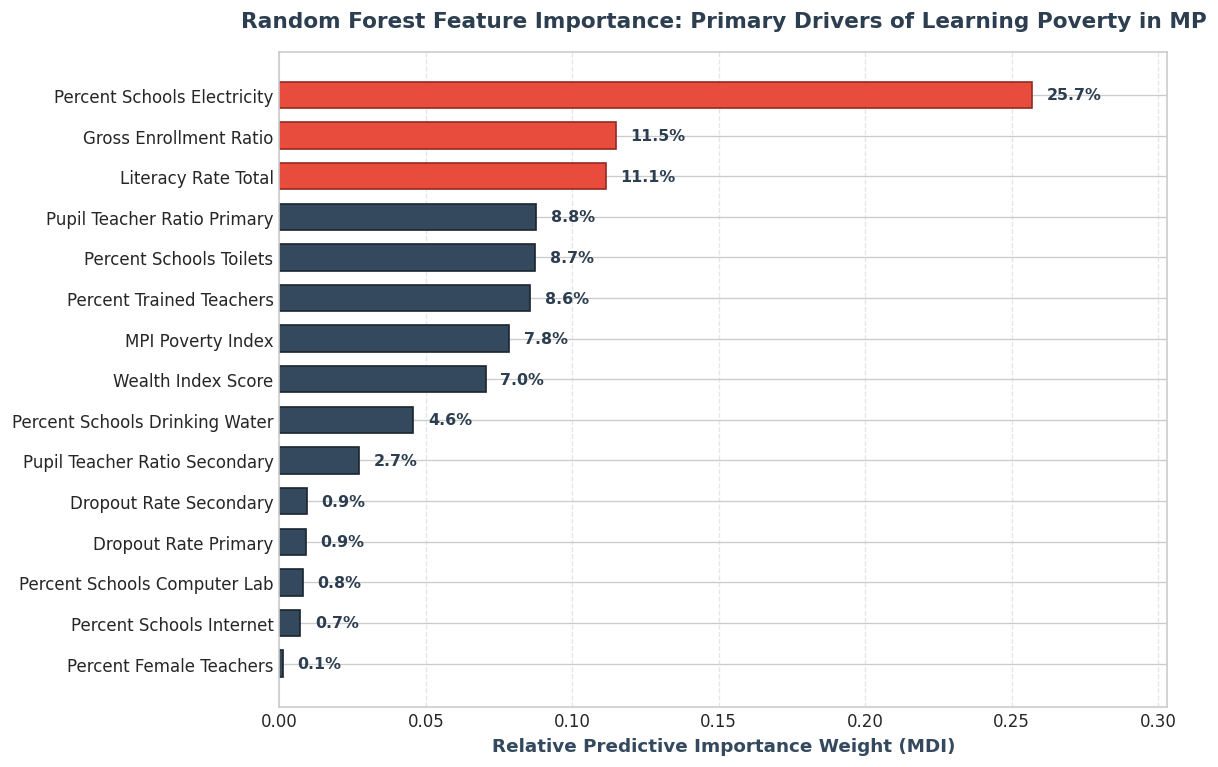

In [5]:
# Extract Feature Importances
importances = rf_regressor.feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature': [c.replace('_', ' ') for c in feature_cols],
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

# Publication-grade Feature Importance Plot
fig, ax = plt.subplots(figsize=(10, 6.5))

bars = ax.barh(
    feature_importance_df['Feature'], 
    feature_importance_df['Importance'],
    color='#34495E',
    edgecolor='#1A252F',
    height=0.65
)

# Highlight top 3 key drivers with distinctive color
for i in range(len(bars) - 3, len(bars)):
    bars[i].set_color(COLOR_HIGH)
    bars[i].set_edgecolor('#922B21')

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.005, bar.get_y() + bar.get_height()/2, f'{w*100:.1f}%', 
            va='center', ha='left', fontsize=9.5, fontweight='bold', color='#2C3E50')

ax.set_title("Random Forest Feature Importance: Primary Drivers of Learning Poverty in MP", 
             fontsize=13, fontweight='bold', pad=15, color='#2C3E50')
ax.set_xlabel("Relative Predictive Importance Weight (MDI)", fontsize=11, fontweight='bold', color='#34495E')
ax.set_xlim(0, max(importances) * 1.18)
ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### 5. Macro Risk Analytics & State-Level GeoAI Overview
Visualizes the overall distribution of educational risk across Madhya Pradesh, displaying the proportion of districts per risk tier, score densities, and top benchmark districts.


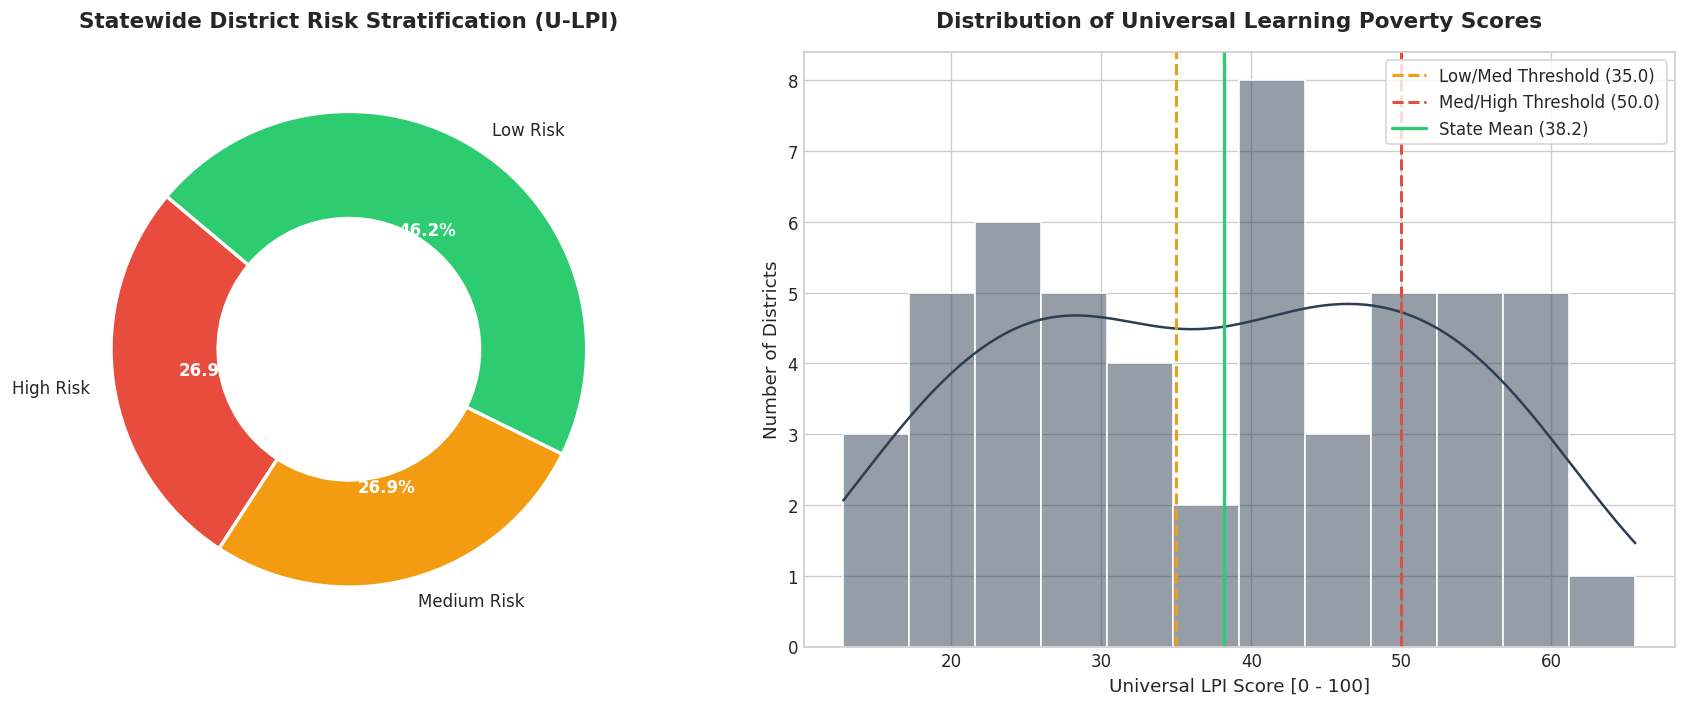


🚨 TOP 5 CRITICAL HIGH-RISK DISTRICTS (Immediate Targeted Intervention Required):


,District,Computed_LPI,Risk_Category,Percent_Schools_Toilets,Percent_Trained_Teachers,MPI_Poverty_Index,Literacy_Rate_Total
0,Sidhi,65.60,High Risk,46.70,41.18,44.23,41.87
1,Ashoknagar,60.59,High Risk,43.78,33.57,48.22,37.69
2,Burhanpur,59.57,High Risk,41.54,34.98,53.55,36.34
3,Umaria,59.01,High Risk,46.04,43.28,46.62,43.56
4,Balaghat,58.78,High Risk,47.26,33.96,53.53,38.22



🏆 TOP 5 LOW-RISK DISTRICTS (Benchmark Model Districts):


,District,Computed_LPI,Risk_Category,Percent_Schools_Toilets,Percent_Trained_Teachers,MPI_Poverty_Index,Literacy_Rate_Total
0,Rewa,12.79,Low Risk,100.00,87.41,5.20,82.54
1,Sagar,15.06,Low Risk,92.45,88.49,3.05,83.53
2,Guna,16.36,Low Risk,94.78,85.59,3.38,82.08
3,Datia,17.32,Low Risk,82.32,85.31,4.92,81.31
4,Chhindwara,17.78,Low Risk,96.26,80.20,8.28,84.30


In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: Semantic Donut Chart of Risk Tiers
tier_counts = df['Risk_Category'].value_counts().reindex(['High Risk', 'Medium Risk', 'Low Risk'])
tier_colors = [COLOR_HIGH, COLOR_MED, COLOR_LOW]

wedges, texts, autotexts = ax1.pie(
    tier_counts.values,
    labels=tier_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=tier_colors,
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2)
)
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_weight('bold')
ax1.set_title('Statewide District Risk Stratification (U-LPI)', fontsize=13, fontweight='bold', pad=15)

# Subplot 2: Density / Histogram Distribution of U-LPI
sns.histplot(df['Computed_LPI'], kde=True, ax=ax2, color=COLOR_PRIMARY, bins=12, edgecolor='white')
ax2.axvline(35.0, color=COLOR_MED, linestyle='--', linewidth=1.8, label='Low/Med Threshold (35.0)')
ax2.axvline(50.0, color=COLOR_HIGH, linestyle='--', linewidth=1.8, label='Med/High Threshold (50.0)')
ax2.axvline(df['Computed_LPI'].mean(), color=COLOR_LOW, linestyle='-', linewidth=2.0, label=f"State Mean ({df['Computed_LPI'].mean():.1f})")
ax2.set_title('Distribution of Universal Learning Poverty Scores', fontsize=13, fontweight='bold', pad=15)
ax2.set_xlabel('Universal LPI Score [0 - 100]', fontsize=11)
ax2.set_ylabel('Number of Districts', fontsize=11)
ax2.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

# Tabular Rankings Preview
display_cols = ['District', 'Computed_LPI', 'Risk_Category', 'Percent_Schools_Toilets', 'Percent_Trained_Teachers', 'MPI_Poverty_Index', 'Literacy_Rate_Total']
top5_high = df.sort_values(by='Computed_LPI', ascending=False).head(5)[display_cols]
print('\n🚨 TOP 5 CRITICAL HIGH-RISK DISTRICTS (Immediate Targeted Intervention Required):')
display(top5_high.reset_index(drop=True))

top5_low = df.sort_values(by='Computed_LPI', ascending=True).head(5)[display_cols]
print('\n🏆 TOP 5 LOW-RISK DISTRICTS (Benchmark Model Districts):')
display(top5_low.reset_index(drop=True))


### 6. District Diagnostic Decision Support System (Tier 3 & 4)
Builds the surgical diagnostic components for each district:
1. **Executive KPI Scorecard**: Formatted HTML badge summarizing district risk, ground-truth LPI, and primary indicators.
2. **Automated Diagnostic Flags ('Attention Panel')**: Programmatically flags metrics in the worst state quartile ($\le 25\text{th}$ percentile for positive metrics like electricity, $\ge 75\text{th}$ percentile for deficits like dropout).
3. **Infrastructure Gap Chart**: Compares basic utilities against critical policy benchmarks (60% Critical Threshold, 80% Target).
4. **Socio-Educational Radar Profile**: Multi-dimensional polar visualization benchmarking the district across 5 core development axes.


In [7]:
# Precalculate statewide quartiles for programmatic attention panel
p25 = df.quantile(0.25, numeric_only=True)
p75 = df.quantile(0.75, numeric_only=True)

def render_district_scorecard(row):
    """Generates a modern, clean HTML KPI Scorecard for administrative briefings."""
    bg_color = row['Risk_Color']
    badge_html = f"""
    <div style="background-color: #F8F9FA; border-left: 8px solid {bg_color}; padding: 18px 24px; border-radius: 8px; margin-bottom: 20px; box-shadow: 0 2px 6px rgba(0,0,0,0.06);">
        <div style="display: flex; justify-content: space-between; align-items: center;">
            <div>
                <h2 style="margin: 0; color: #2C3E50; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;">{row['District']} <span style="font-size: 14px; font-weight: normal; color: #7F8C8D;">(Madhya Pradesh)</span></h2>
                <p style="margin: 4px 0 0 0; color: #7F8C8D; font-size: 13px;">Phase-I Educational Decision-Support Assessment</p>
            </div>
            <div style="text-align: right;">
                <span style="background-color: {bg_color}; color: white; padding: 6px 16px; border-radius: 20px; font-weight: bold; font-size: 13px; text-transform: uppercase; letter-spacing: 0.5px;">
                    {row['Risk_Category']}
                </span>
                <div style="font-size: 26px; font-weight: 800; color: #2C3E50; margin-top: 4px;">LPI: {row['Computed_LPI']:.2f}</div>
            </div>
        </div>
        <hr style="border: none; border-top: 1px solid #E2E8F0; margin: 12px 0;">
        <div style="display: grid; grid-template-columns: repeat(4, 1fr); gap: 12px; text-align: center;">
            <div style="background: white; padding: 10px; border-radius: 6px; border: 1px solid #EDF2F7;">
                <span style="font-size: 11px; color: #718096; text-transform: uppercase;">Literacy Rate</span>
                <div style="font-size: 16px; font-weight: bold; color: #2D3748;">{row['Literacy_Rate_Total']:.1f}%</div>
            </div>
            <div style="background: white; padding: 10px; border-radius: 6px; border: 1px solid #EDF2F7;">
                <span style="font-size: 11px; color: #718096; text-transform: uppercase;">Secondary Dropout</span>
                <div style="font-size: 16px; font-weight: bold; color: {'#E74C3C' if row['Dropout_Rate_Secondary'] > p75['Dropout_Rate_Secondary'] else '#2D3748'};">{row['Dropout_Rate_Secondary']:.1f}%</div>
            </div>
            <div style="background: white; padding: 10px; border-radius: 6px; border: 1px solid #EDF2F7;">
                <span style="font-size: 11px; color: #718096; text-transform: uppercase;">Secondary PTR</span>
                <div style="font-size: 16px; font-weight: bold; color: {'#E74C3C' if row['Pupil_Teacher_Ratio_Secondary'] > p75['Pupil_Teacher_Ratio_Secondary'] else '#2D3748'};">{row['Pupil_Teacher_Ratio_Secondary']:.1f}</div>
            </div>
            <div style="background: white; padding: 10px; border-radius: 6px; border: 1px solid #EDF2F7;">
                <span style="font-size: 11px; color: #718096; text-transform: uppercase;">School Electrification</span>
                <div style="font-size: 16px; font-weight: bold; color: {'#E74C3C' if row['Percent_Schools_Electricity'] < p25['Percent_Schools_Electricity'] else '#2D3748'};">{row['Percent_Schools_Electricity']:.1f}%</div>
            </div>
        </div>
    </div>
    """
    display(HTML(badge_html))

def render_attention_panel(row):
    """Generates automated diagnostic flags for metrics in the worst state quartile."""
    alerts = []
    
    # Positive metrics in worst quartile (< 25th percentile)
    if row['Percent_Schools_Electricity'] <= p25['Percent_Schools_Electricity']:
        alerts.append((
            "CRITICAL INFRASTRUCTURE DEFICIT: Electrification",
            f"Only {row['Percent_Schools_Electricity']:.1f}% schools electrified (Worst statewide quartile <= {p25['Percent_Schools_Electricity']:.1f}%).",
            "Prioritize grid/solar connection under Samagra Shiksha."
        ))
    if row['Percent_Schools_Toilets'] <= p25['Percent_Schools_Toilets']:
        alerts.append((
            "SANITATION DEFICIT: Functional Toilets",
            f"Toilet saturation at {row['Percent_Schools_Toilets']:.1f}% (State bottom quartile <= {p25['Percent_Schools_Toilets']:.1f}%).",
            "Urgent sanitation construction required to safeguard girl retention."
        ))
    if row['Percent_Schools_Drinking_Water'] <= p25['Percent_Schools_Drinking_Water']:
        alerts.append((
            "BASIC UTILITY DEFICIT: Drinking Water",
            f"Drinking water access at {row['Percent_Schools_Drinking_Water']:.1f}%.",
            "Deploy Jal Jeevan Mission piped connections to all campuses."
        ))
    if row['Percent_Schools_Computer_Lab'] <= p25['Percent_Schools_Computer_Lab']:
        alerts.append((
            "DIGITAL DIVIDE: Computer Labs",
            f"Only {row['Percent_Schools_Computer_Lab']:.1f}% computer lab availability.",
            "Establish smart classroom cluster facilities."
        ))
        
    # Deficit metrics in worst quartile (> 75th percentile)
    if row['Dropout_Rate_Secondary'] >= p75['Dropout_Rate_Secondary']:
        alerts.append((
            "ACADEMIC ATTRITION: High Secondary Dropout",
            f"Dropout rate sits at {row['Dropout_Rate_Secondary']:.1f}% (Worst quartile >= {p75['Dropout_Rate_Secondary']:.1f}%).",
            "Deploy localized attendance trackers, parent counseling, and conditional support."
        ))
    if row['Pupil_Teacher_Ratio_Secondary'] >= p75['Pupil_Teacher_Ratio_Secondary']:
        alerts.append((
            "TEACHER SHORTAGE: Elevated PTR",
            f"Secondary PTR of {row['Pupil_Teacher_Ratio_Secondary']:.1f}:1 exceeds state bottom quartile (>= {p75['Pupil_Teacher_Ratio_Secondary']:.1f}:1).",
            "Expedite secondary cadre teacher transfers to decongest classrooms."
        ))

    print("-" * 80)
    print("🚨 IMMEDIATE ATTENTION PANEL: AUTOMATED DIAGNOSTIC FLAGS")
    print("-" * 80)
    if not alerts:
        print("✓ No worst-quartile bottlenecks detected. District indicators are at or above state medians.")
    else:
        for idx, (title, desc, rec) in enumerate(alerts, 1):
            print(f"[{idx}] {title}")
            print(f"    • Finding : {desc}")
            print(f"    • Action  : {rec}")
    print("-" * 80)

def plot_district_diagnostics(row):
    """Generates side-by-side Infrastructure Gap Chart and Socio-Educational Radar Profile."""
    fig = plt.figure(figsize=(15, 5.5))
    
    # 1. Infrastructure Bar Chart
    ax1 = fig.add_subplot(1, 2, 1)
    infra_labels = ['Electricity', 'Drinking Water', 'Toilets', 'Computer Lab', 'Internet']
    infra_vals = [
        row['Percent_Schools_Electricity'],
        row['Percent_Schools_Drinking_Water'],
        row['Percent_Schools_Toilets'],
        row['Percent_Schools_Computer_Lab'],
        row['Percent_Schools_Internet']
    ]
    bar_colors = [COLOR_HIGH if v < 60 else (COLOR_MED if v < 80 else COLOR_LOW) for v in infra_vals]
    
    bars = ax1.bar(infra_labels, infra_vals, color=bar_colors, edgecolor='#2C3E50', linewidth=1, width=0.55)
    for bar in bars:
        h = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2, h + 2, f'{h:.1f}%', ha='center', va='bottom', fontsize=9.5, fontweight='bold')
        
    ax1.axhline(60, color=COLOR_HIGH, linestyle='--', linewidth=1.8, label='Critical Deficit Threshold (60%)')
    ax1.axhline(80, color=COLOR_LOW, linestyle='--', linewidth=1.8, label='Target Saturation (80%)')
    ax1.set_ylim(0, 115)
    ax1.set_ylabel("Coverage (%)", fontsize=11, fontweight='bold')
    ax1.set_title(f"Infrastructure Saturation & Gaps: {row['District']}", fontsize=12, fontweight='bold', pad=12, color='#2C3E50')
    ax1.legend(loc='upper right', frameon=True, fontsize=8.5)
    ax1.grid(axis='y', linestyle=':', alpha=0.6)
    
    # 2. Socio-Educational Polar Radar Profile
    ax2 = fig.add_subplot(1, 2, 2, polar=True)
    radar_labels = [
        'Literacy Rate', 
        'Trained Teachers', 
        'Gross Enrollment', 
        'Electricity Access',
        'Wealth Index'
    ]
    # Normalized scores on a 0-100 scale
    radar_vals = [
        row['Literacy_Rate_Total'],
        row['Percent_Trained_Teachers'],
        row['Gross_Enrollment_Ratio'],
        row['Percent_Schools_Electricity'],
        row['Wealth_Index_Score']
    ]
    
    num_vars = len(radar_labels)
    angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
    radar_vals += radar_vals[:1]
    angles += angles[:1]
    
    ax2.plot(angles, radar_vals, color=row['Risk_Color'], linewidth=2.5, linestyle='solid')
    ax2.fill(angles, radar_vals, color=row['Risk_Color'], alpha=0.25)
    ax2.set_xticks(angles[:-1])
    ax2.set_xticklabels(radar_labels, fontsize=9.5, fontweight='bold', color='#2C3E50')
    ax2.set_ylim(0, 100)
    ax2.set_yticks([25, 50, 75, 100])
    ax2.set_yticklabels(['25', '50', '75', '100'], fontsize=8, color='#7F8C8D')
    ax2.set_title(f"Socio-Educational Radar Profile: {row['District']}", fontsize=12, fontweight='bold', pad=20, color='#2C3E50')
    
    plt.tight_layout()
    plt.show()

def analyze_district(district_name):
    """Master district analysis invocation."""
    match = df[df['District'] == district_name]
    if match.empty:
        print(f"❌ District '{district_name}' not found.")
        return
    row = match.iloc[0]
    render_district_scorecard(row)
    render_attention_panel(row)
    plot_district_diagnostics(row)

print("✓ Diagnostic Decision Support System functions successfully compiled.")


✓ Diagnostic Decision Support System functions successfully compiled.


### 7. Interactive Decision-Support Dashboard Launch
Select any of the 52 districts of Madhya Pradesh using the interactive dropdown below to dynamically update the executive scorecard, diagnostic alert flags, infrastructure gap chart, and socio-educational radar profile.


In [8]:
district_dropdown = Dropdown(
    options=sorted(df['District'].unique().tolist()),
    value='Alirajpur' if 'Alirajpur' in df['District'].values else df['District'].iloc[0],
    description='District:',
    style={'description_width': 'initial'},
    layout={'width': '380px'}
)

interact(analyze_district, district_name=district_dropdown);


interactive(children=(Dropdown(description='District:', index=1, layout=Layout(width='380px'), options=('Agar …

### 8. 'What-If' Counterfactual Policy Simulator (Tier 4)
Simulates policy resource allocation scenarios for any selected district.  
Allows administrators to test targeted interventions (e.g., increasing school electrification, reducing secondary dropout, expanding teacher staffing) and observe both:
1. **Analytical Ground-Truth Impact** ($\Delta \text{LPI}$ calculated from equation).
2. **Predictive Machine Learning Projection** (Random Forest response surface).


In [9]:
def simulate_policy_intervention(district_name, toilet_delta, elec_delta, training_delta, dropout_reduction):
    """
    Simulates counterfactual interventions across the 5 pillars:
    - toilet_delta: Percentage point increase in functional toilets (WASH).
    - elec_delta: Percentage point increase in school electrification.
    - training_delta: Percentage point increase in certified trained teachers.
    - dropout_reduction: Percentage point decrease in secondary dropout.
    """
    match = df[df['District'] == district_name]
    if match.empty:
        return
    row = match.iloc[0].copy()
    
    # Baseline Status
    base_lpi = row['Computed_LPI']
    base_tier = row['Risk_Category']
    
    # Counterfactual Values
    sim_row = row.copy()
    sim_row['Percent_Schools_Toilets'] = min(100.0, row['Percent_Schools_Toilets'] + toilet_delta)
    sim_row['Percent_Schools_Electricity'] = min(100.0, row['Percent_Schools_Electricity'] + elec_delta)
    sim_row['Percent_Trained_Teachers'] = min(100.0, row['Percent_Trained_Teachers'] + training_delta)
    sim_row['Dropout_Rate_Secondary'] = max(0.0, row['Dropout_Rate_Secondary'] - dropout_reduction)
    
    # Calculate Ground-Truth Simulated U-LPI
    sim_lpi = compute_universal_lpi(sim_row)
    sim_tier = assign_risk_category(sim_lpi)
    delta_lpi = sim_lpi - base_lpi
    
    # Machine Learning Projection
    sim_vector = sim_row[feature_cols].copy()
    sim_ml_pred = rf_regressor.predict([sim_vector])[0]
    
    # Render Simulation Comparison Card
    sim_color = palette_map[sim_tier]
    base_color = palette_map[base_tier]
    
    html_sim = f"""
    <div style="background-color: #FFFFFF; border: 1px solid #CBD5E0; border-radius: 8px; padding: 18px 24px; margin-top: 15px; box-shadow: 0 4px 6px rgba(0,0,0,0.05);">
        <h3 style="margin: 0 0 12px 0; color: #2C3E50;">Multi-Pillar Policy Simulator: {district_name}</h3>
        <div style="display: grid; grid-template-columns: repeat(3, 1fr); gap: 15px; text-align: center;">
            <div style="padding: 12px; border-radius: 6px; background: #F7FAFC; border: 1px solid #E2E8F0;">
                <span style="font-size: 11px; color: #718096; text-transform: uppercase;">Baseline Status</span>
                <div style="font-size: 20px; font-weight: bold; color: {base_color}; margin: 4px 0;">{base_lpi:.2f} ({base_tier})</div>
                <span style="font-size: 11px; color: #A0AEC0;">Toilets: {row['Percent_Schools_Toilets']:.1f}% | Trained: {row['Percent_Trained_Teachers']:.1f}% | Dropout: {row['Dropout_Rate_Secondary']:.1f}%</span>
            </div>
            <div style="padding: 12px; border-radius: 6px; background: #F7FAFC; border: 1px solid #E2E8F0;">
                <span style="font-size: 11px; color: #718096; text-transform: uppercase;">Simulated Status</span>
                <div style="font-size: 20px; font-weight: bold; color: {sim_color}; margin: 4px 0;">{sim_lpi:.2f} ({sim_tier})</div>
                <span style="font-size: 11px; color: #A0AEC0;">Toilets: {sim_row['Percent_Schools_Toilets']:.1f}% | Trained: {sim_row['Percent_Trained_Teachers']:.1f}% | Dropout: {sim_row['Dropout_Rate_Secondary']:.1f}%</span>
            </div>
            <div style="padding: 12px; border-radius: 6px; background: #F7FAFC; border: 1px solid #E2E8F0;">
                <span style="font-size: 11px; color: #718096; text-transform: uppercase;">Policy Delta (Impact)</span>
                <div style="font-size: 20px; font-weight: bold; color: {'#2ECC71' if delta_lpi < 0 else '#E74C3C'}; margin: 4px 0;">
                    {delta_lpi:+.2f} pts
                </div>
                <span style="font-size: 11px; color: #718096;">ML Projected Score: {sim_ml_pred:.2f}</span>
            </div>
        </div>
    </div>
    """
    display(HTML(html_sim))

# Launch Interactive Simulation Sliders
interact(
    simulate_policy_intervention,
    district_name=Dropdown(options=sorted(df[df['Risk_Category'] == 'High Risk']['District'].unique().tolist()), description='High-Risk District:'),
    toilet_delta=IntSlider(min=0, max=40, step=5, value=20, description='Toilet Upgrade (%p):'),
    elec_delta=IntSlider(min=0, max=40, step=5, value=15, description='Elec Upgrade (%p):'),
    training_delta=IntSlider(min=0, max=40, step=5, value=20, description='Teacher Training (%p):'),
    dropout_reduction=FloatSlider(min=0.0, max=15.0, step=1.0, value=5.0, description='Dropout Drop (%p):')
);


interactive(children=(Dropdown(description='High-Risk District:', options=('Anuppur', 'Ashoknagar', 'Balaghat'…

### 9. Administrative Export & Deliverables
Compiles the high-risk district intervention report with priority flags and exports to CSV for district administration and planning portfolios.


In [10]:
# Export High Risk Districts with Priority Intervention Flags
high_risk_df = df[df['Risk_Category'] == 'High Risk'].copy()

# Add programmatic flags
high_risk_df['Flag_Critical_Infrastructure'] = (
    (high_risk_df['Percent_Schools_Electricity'] < 60) |
    (high_risk_df['Percent_Schools_Toilets'] < 60) |
    (high_risk_df['Percent_Schools_Drinking_Water'] < 60)
)

high_risk_df['Flag_Critical_Education'] = (
    (high_risk_df['Pupil_Teacher_Ratio_Secondary'] > 35) |
    (high_risk_df['Dropout_Rate_Secondary'] > 25)
)

# Export paths
export_dirs = [
    os.path.join('..', 'data', 'outputs'),
    os.path.join('data', 'outputs'),
    '.'
]
export_dir = next((d for d in export_dirs if os.path.exists(d)), '.')
export_path = os.path.join(export_dir, 'high_risk_districts_report.csv')

high_risk_df.to_csv(export_path, index=False)
print("=" * 80)
print(f"✓ High-Risk Priority Report exported to: {os.path.abspath(export_path)}")
print(f"✓ Total High-Risk Districts Flagged: {len(high_risk_df)}")
print(f"  - Districts with Critical Infrastructure Gaps: {high_risk_df['Flag_Critical_Infrastructure'].sum()}")
print(f"  - Districts with Critical Academic Attrition: {high_risk_df['Flag_Critical_Education'].sum()}")
print("=" * 80)
display(high_risk_df[['District', 'Computed_LPI', 'Flag_Critical_Infrastructure', 'Flag_Critical_Education']].head(6))


✓ High-Risk Priority Report exported to: G:\EPICS\data\outputs\high_risk_districts_report.csv
✓ Total High-Risk Districts Flagged: 14
  - Districts with Critical Infrastructure Gaps: 14
  - Districts with Critical Academic Attrition: 14


,District,Computed_LPI,Flag_Critical_Infrastructure,Flag_Critical_Education
2,Anuppur,52.97,True,True
3,Ashoknagar,60.59,True,True
4,Balaghat,58.78,True,True
5,Barwani,53.60,True,True
9,Burhanpur,59.57,True,True
18,Gwalior,51.23,True,True
